### Develop a computational model to simulate the movement of particles through multi-dimensional space using montocarlo methods. Use a probabilistic solution method to determine the trajectory of the walker over a defined number of discret step .spcace 2d grid of your choice. The agent should take actions to reach a predetermined goal on the grid across all simulations.

## Step 1: Define the objective

The objective of this project is to develop a computational model that simulates the movement of a particle (agent) in a two-dimensional grid using the Monte Carlo method.

The agent starts from a fixed position and tries to reach a predetermined goal. At each discrete time step, it selects an action probabilistically.

We repeat the simulation multiple times to analyze the different trajectories and calculate the probability of reaching the goal.

## Step 2: Import the required libraries

Explanation:
- random: Used to select the agent's movement probabilistically.
- matplotlib.pyplot: Used to visualize the trajectory of the agent on the 2D grid.

In [1]:
import random
import matplotlib.pyplot as plt

## Step 3: Define the grid environment

In [2]:
# -------------------------------------------------------
# MONTE CARLO RANDOM WALK ON A 2D GRID
# -------------------------------------------------------

# Grid parameters
GRID_SIZE = 15
START = (0, 0)
GOAL = (12, 10)

In [3]:
# Maximum number of discrete steps in each simulation
MAX_STEPS = 100

In [4]:
# Number of Monte Carlo simulations
NUM_SIMULATIONS = 500


We create a 15 × 15 grid that represents the environment.
- The agent starts at position (0, 0).
- The predetermined goal is (12, 10).
- The agent can take a maximum of 100 steps per simulation.
- We perform 500 independent Monte Carlo simulations.
The starting position and goal remain the same in every simulation.


## Step 4: Define possible actions

In [5]:
# Possible actions
ACTIONS = {
    "up": (0, 1),
    "down": (0, -1),
    "left": (-1, 0),
    "right": (1, 0)
}

At every step, the agent can choose one of four actions.
Action	Change in position
Up	(0, +1)
Down (0, -1)
Left  (-1, 0)
Right  (+1, 0)
The agent moves only one grid cell at a time.

## Step 5: Calculate distance to the goal

In [6]:
def distance_to_goal(position):
    """
    Calculate Manhattan distance between the agent and the goal.
    """
    x, y = position
    gx, gy = GOAL

    return abs(gx - x) + abs(gy - y)


We use Manhattan distance to calculate how far the agent is from the goal.



Where:
- (x,y)) represents the current position.
- ((x_g,y_g)) represents the goal position.
  
For example, from (0, 0) to (12, 10):

D=|12-0|+|10-0|=22

Therefore, the minimum number of steps required to reach the goal is 22.

## Step 6: Check valid positions

In [7]:
def valid_position(position):
    """
    Check whether a position is inside the grid.
    """
    x, y = position

    return 0 <= x < GRID_SIZE and 0 <= y < GRID_SIZE

This function checks whether the agent remains inside the grid boundaries.

For a 15 × 15 grid, valid coordinates range from 0 to 14.

If the agent tries to move outside the grid, that action is not allowed.

## Step 7: Implement probabilistic action selection

In [8]:
def choose_action(position):
    """
    Probabilistically choose an action.

    Actions that move the agent closer to the goal receive
    a higher probability, but other actions are still possible.
    """

    possible_actions = []
    weights = []

    current_distance = distance_to_goal(position)

    for action, movement in ACTIONS.items():

        new_position = (
            position[0] + movement[0],
            position[1] + movement[1]
        )

        # Ignore moves outside the grid
        if not valid_position(new_position):
            continue

        new_distance = distance_to_goal(new_position)

        # Give higher probability to moves toward the goal
        if new_distance < current_distance:
            weight = 0.7
        elif new_distance == current_distance:
            weight = 0.2
        else:
            weight = 0.1

        possible_actions.append(action)
        weights.append(weight)

    # Monte Carlo sampling
    return random.choices(
        possible_actions,
        weights=weights,
        k=1
    )[0]


This is the most important part of the Monte Carlo simulation.

Instead of choosing a fixed direction, the agent selects an action randomly using weighted probabilities.
Movement	Weight
Toward the goal	0.7
No change in distance	0.2
Away from the goal	0.1
These values are relative weights, not final probabilities. Python normalizes the weights of the available actions so their probabilities add up to 1.

For example, if two valid actions move closer to the goal and two move away, each closer action has probability

P(closer action)=0.7/0.7+0.7+0.1+0.1=0.4375


The agent is more likely to move toward the goal, but random movements are still possible.

## Step 8: Run a single simulation

In [9]:
def run_simulation():
    """
    Run one Monte Carlo random-walk simulation.
    """

    position = START
    trajectory = [position]

    for step in range(MAX_STEPS):

        # Goal reached
        if position == GOAL:
            return trajectory, True

        action = choose_action(position)

        dx, dy = ACTIONS[action]

        new_position = (
            position[0] + dx,
            position[1] + dy
        )

        if valid_position(new_position):
            position = new_position

        trajectory.append(position)

    return trajectory, position == GOAL

This function simulates the movement of one agent.

The process is:
1. Initialize the agent at the starting position.
2. Check whether the goal has been reached.
3. Select an action using probabilistic decision-making.
4. Update the agent's position.
5. Store the new position in the trajectory.
6. Repeat until the goal is reached or the maximum number of steps is completed.
The function returns the trajectory and a Boolean value indicating whether the agent reached the goal.

## Step 9: Perform multiple Monte Carlo simulations

In [10]:
# -------------------------------------------------------
# RUN MANY MONTE CARLO SIMULATIONS
# -------------------------------------------------------

successful_runs = 0
successful_trajectories = []

for simulation in range(NUM_SIMULATIONS):

    trajectory, success = run_simulation()

    if success:
        successful_runs += 1
        successful_trajectories.append(trajectory)

We repeat the random-walk simulation 500 times.

Every simulation uses the same starting point and goal, but the agent can follow a different trajectory due to random action selection.

We count the successful simulations and store their trajectories for visualization.

## Step 10: Calculate the success probability

In [11]:
# -------------------------------------------------------
# RESULTS
# -------------------------------------------------------

success_rate = successful_runs / NUM_SIMULATIONS

print("Monte Carlo Particle Simulation")
print("--------------------------------")
print("Grid size:", GRID_SIZE, "x", GRID_SIZE)
print("Starting position:", START)
print("Goal position:", GOAL)
print("Number of simulations:", NUM_SIMULATIONS)
print("Maximum steps:", MAX_STEPS)
print("Successful simulations:", successful_runs)
print(f"Success rate: {success_rate:.2%}")

Monte Carlo Particle Simulation
--------------------------------
Grid size: 15 x 15
Starting position: (0, 0)
Goal position: (12, 10)
Number of simulations: 500
Maximum steps: 100
Successful simulations: 500
Success rate: 100.00%


The success rate is estimated using:

P(success)=
N_successful / N_total


For example, if 450 out of 500 simulations reach the goal:
P(success)=450/500=0.90


This corresponds to a 90% success rate.

Note: This is an illustrative example. The actual success rate depends on the random simulation results.

## Step 11: Visualize the trajectory

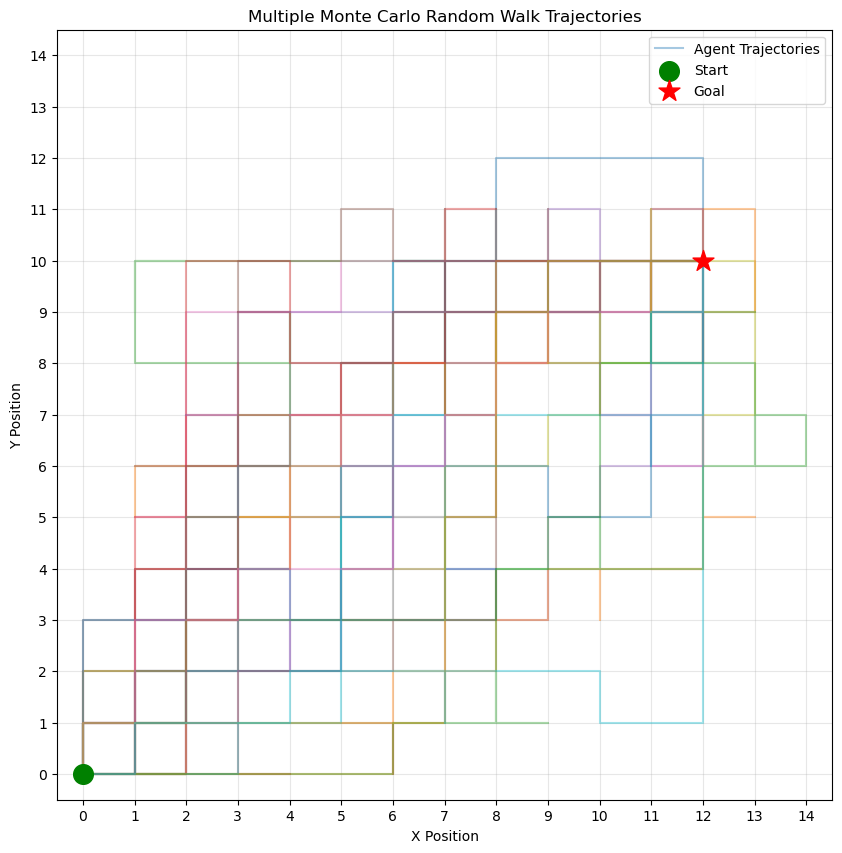

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

# Plot multiple successful trajectories
for i, trajectory in enumerate(successful_trajectories[:30]):

    x_values = [position[0] for position in trajectory]
    y_values = [position[1] for position in trajectory]

    plt.plot(
        x_values,
        y_values,
        alpha=0.4,
        linewidth=1.5,
        label="Agent Trajectories" if i == 0 else None
    )

# Starting position
plt.scatter(
    START[0],
    START[1],
    color="green",
    s=200,
    marker="o",
    label="Start",
    zorder=5
)

# Goal position
plt.scatter(
    GOAL[0],
    GOAL[1],
    color="red",
    s=250,
    marker="*",
    label="Goal",
    zorder=5
)

plt.xlim(-0.5, GRID_SIZE - 0.5)
plt.ylim(-0.5, GRID_SIZE - 0.5)

plt.xticks(range(GRID_SIZE))
plt.yticks(range(GRID_SIZE))

plt.xlabel("X Position")
plt.ylabel("Y Position")

plt.title("Multiple Monte Carlo Random Walk Trajectories")

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

This code displays one randomly selected successful trajectory.
- The green point represents the starting position.
- The red star represents the predetermined goal.
- The connected line represents the path followed by the agent.
The graph helps us understand how probabilistic decisions influence the movement of the agent.

## Step 12: Results and observations


After running the simulations, we can observe that the agent follows different trajectories even though the starting position and goal remain fixed.

The agent generally moves toward the goal because actions that reduce the distance have higher weights. However, due to randomness, it may sometimes move away from the goal.

Some trajectories may be longer than others. The success rate measures how often the agent reaches the goal within the maximum number of steps.

## Step 13: Conclusion


In this project, I developed a computational model to simulate the movement of an agent in a two-dimensional grid using Monte Carlo methods.

The agent uses probabilistic decision-making to select its movement at each discrete time step. The starting position and goal remain fixed throughout all simulations.

By repeating the simulation multiple times, we analyzed the different trajectories and estimated the probability of successfully reaching the goal.

The results demonstrate how Monte Carlo methods can be used to model stochastic movement and goal-directed decision-making in a discrete environment.